# NASA POWER column glossary

The first cell loads daily NASA POWER observations for the Eastern Washington wheat analysis. The table below explains each column, its usual unit, and why it matters for crop conditions.

| Column | Meaning | Unit | Wheat-growth relevance |
|---|---|---|---|
| `LAT` | Latitude of the observation point | Decimal degrees | Identifies the geographic location |
| `LON` | Longitude of the observation point | Decimal degrees | Identifies the geographic location |
| `date` | Calendar date of the observation | YYYY-MM-DD | Supports seasonal and time-series analysis |
| `T2M` | Average air temperature at 2 meters | °C | Influences development rate and growing-season conditions |
| `T2M_MAX` | Maximum air temperature at 2 meters | °C | High values can indicate heat stress and accelerated grain development |
| `T2M_MIN` | Minimum air temperature at 2 meters | °C | Low values can indicate frost risk during emergence, overwintering, and regrowth |
| `RH2M` | Relative humidity at 2 meters | % | Helps characterize disease pressure and atmospheric moisture |
| `WS2M` | Wind speed at 2 meters | m/s | Affects evapotranspiration, drying, lodging, and spray conditions |
| `ALLSKY_SFC_SW_DWN` | All-sky surface shortwave downward radiation | kWh/m²/day | Represents solar energy available for photosynthesis and biomass growth |
| `PRECTOTCORR` | Bias-corrected precipitation | mm/day | Indicates daily water input for soil moisture and crop growth |

The dataset does not currently include `GWETROOT` (root-zone wetness) or NDVI. Those variables should be added from compatible NASA or satellite products before making stronger claims about root-zone water stress or vegetation development.


In [1]:
from pathlib import Path

import pandas as pd
from numbers_parser import Document

numbers_path = Path(
    "/Users/warrenbuenarte/Library/CloudStorage/OneDrive-Personal/"
    "power_df2_c.numbers"
)
if not numbers_path.exists():
    raise FileNotFoundError(f"Dataset not found: {numbers_path}")

document = Document(str(numbers_path))
table = document.sheets[0].tables[0]
rows = [[cell.value for cell in row] for row in table.rows()]
if not rows:
    raise ValueError("The Numbers workbook does not contain any rows")

df = pd.DataFrame(rows[1:], columns=rows[0])
df.head()

,LAT,LON,date,T2M,T2M_MAX,T2M_MIN,RH2M,WS2M,ALLSKY_SFC_SW_DWN,PRECTOTCORR
0,45.5,-122.5,2020-01-01,7.81,9.57,5.05,96.90,0.89,3.58,15.02
1,45.5,-122.5,2020-01-02,5.92,8.06,4.17,97.68,1.12,2.09,3.50
2,45.5,-122.5,2020-01-03,9.00,12.41,5.69,79.60,1.32,3.98,5.16
3,45.5,-122.5,2020-01-04,4.59,6.23,3.02,95.69,0.97,3.87,9.11
4,45.5,-122.5,2020-01-05,4.20,6.15,3.03,96.68,1.09,3.30,14.83


# NASA POWER dataset experimentation

This notebook starts with the NASA POWER dataset exported from Apple Numbers. Use `df` for climate exploration, cleaning, visualization, and predictive-model experiments.

The first cell requires the `pandas` and `numbers-parser` packages in the active notebook kernel.

## Eastern Washington wheat modeling baseline

The dataset contains NASA POWER weather variables but no measured wheat yield, disease, or stress labels. The following experiments therefore use transparent environmental stress proxies. They are useful for prototyping the pipeline, not for agronomic recommendations or validated crop predictions.


In [2]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler

model_df = df.copy()
model_df["date"] = pd.to_datetime(model_df["date"])
numeric_columns = [
    "T2M", "T2M_MAX", "T2M_MIN", "RH2M", "WS2M",
    "ALLSKY_SFC_SW_DWN", "PRECTOTCORR",
]
model_df[numeric_columns] = model_df[numeric_columns].apply(pd.to_numeric, errors="coerce")
model_df = model_df.dropna(subset=numeric_columns + ["date"]).sort_values("date").reset_index(drop=True)
model_df["month"] = model_df["date"].dt.month
model_df["doy"] = model_df["date"].dt.dayofyear

# Proxy components: heat, frost, and low daily precipitation.
model_df["heat_stress"] = np.clip((model_df["T2M_MAX"] - 30) / 10, 0, 1)
model_df["frost_stress"] = np.clip((0 - model_df["T2M_MIN"]) / 10, 0, 1)
model_df["dry_stress"] = np.clip((1 - model_df["PRECTOTCORR"]) / 1, 0, 1)
model_df["stress_risk_score"] = (
    0.45 * model_df["heat_stress"]
    + 0.25 * model_df["frost_stress"]
    + 0.30 * model_df["dry_stress"]
)
model_df[["date", "stress_risk_score"]].head()


,date,stress_risk_score
0,2020-01-01,0.000
1,2020-01-01,0.000
2,2020-01-01,0.000
3,2020-01-01,0.000
4,2020-01-01,0.112


## Weighted scoring model

The score weights heat stress most heavily, followed by dry conditions and frost. These weights are starting assumptions for experimentation and should be replaced with crop- and region-specific agronomic evidence.


In [3]:
daily_risk = model_df[["date", "stress_risk_score"]].copy()
daily_risk["risk_band"] = pd.cut(
    daily_risk["stress_risk_score"],
    bins=[-0.01, 0.33, 0.66, 1.0],
    labels=["lower", "moderate", "higher"],
)
daily_risk.groupby("risk_band", observed=False).size().to_frame("days")


,days
risk_band,
lower,12449
moderate,2129
higher,38


## Environmental-zone clustering

K-Means groups days with similar weather conditions. It identifies environmental regimes, not geographic field boundaries; add field coordinates or raster-derived features before interpreting clusters spatially.


In [4]:
cluster_features = [
    "T2M", "T2M_MAX", "T2M_MIN", "RH2M", "WS2M",
    "ALLSKY_SFC_SW_DWN", "PRECTOTCORR",
]
cluster_input = StandardScaler().fit_transform(model_df[cluster_features])
cluster_model = KMeans(n_clusters=3, random_state=42, n_init=10)
model_df["environmental_zone"] = cluster_model.fit_predict(cluster_input)
zone_summary = model_df.groupby("environmental_zone")[cluster_features].mean().round(2)
zone_summary


,T2M,T2M_MAX,T2M_MIN,RH2M,WS2M,ALLSKY_SFC_SW_DWN,PRECTOTCORR
environmental_zone,,,,,,,
0,6.94,9.32,4.57,93.89,0.85,5.27,15.50
1,16.93,23.71,10.54,64.00,0.93,21.36,0.55
2,2.17,6.31,-1.32,85.31,1.18,8.23,1.98


## Environmental zones in depth

Each K-Means zone is a group of observations with similar standardized weather features. The profiles below describe the dominant climate conditions, stress exposure, seasonal behavior, and possible wheat-management relevance. These are exploratory environmental regimes, not official agroclimate classifications.


In [5]:
zone_features = [
    "T2M", "T2M_MAX", "T2M_MIN", "RH2M", "WS2M",
    "ALLSKY_SFC_SW_DWN", "PRECTOTCORR",
]
zone_profile = model_df.groupby("environmental_zone")[zone_features].mean()
zone_profile["observations"] = model_df.groupby("environmental_zone").size()
zone_profile["share_pct"] = zone_profile["observations"] / len(model_df) * 100
zone_profile["mean_stress_risk"] = model_df.groupby("environmental_zone")["stress_risk_score"].mean()
zone_profile["higher_risk_share_pct"] = (
    model_df.assign(higher_risk=model_df["stress_risk_score"] >= 0.66)
    .groupby("environmental_zone")["higher_risk"]
    .mean()
    .mul(100)
)
zone_profile = zone_profile.round(2)
zone_profile


,T2M,T2M_MAX,T2M_MIN,RH2M,WS2M,ALLSKY_SFC_SW_DWN,PRECTOTCORR,observations,share_pct,mean_stress_risk,higher_risk_share_pct
environmental_zone,,,,,,,,,,,
0,6.94,9.32,4.57,93.89,0.85,5.27,15.50,1775,12.14,0.01,0.0
1,16.93,23.71,10.54,64.00,0.93,21.36,0.55,6281,42.97,0.25,0.6
2,2.17,6.31,-1.32,85.31,1.18,8.23,1.98,6560,44.88,0.18,0.0


In [6]:
overall_means = model_df[zone_features].mean()
overall_stds = model_df[zone_features].std().replace(0, np.nan)
zone_z_scores = ((zone_profile[zone_features] - overall_means) / overall_stds).round(2)

zone_labels = {}
for zone, profile in zone_profile.iterrows():
    if profile["T2M"] < overall_means["T2M"] and profile["PRECTOTCORR"] < overall_means["PRECTOTCORR"]:
        label = "Cool and dry / frost-prone"
    elif profile["PRECTOTCORR"] > overall_means["PRECTOTCORR"]:
        label = "Warm and wet / humid"
    else:
        label = "Warm and relatively dry"
    zone_labels[zone] = label

zone_profile.insert(0, "regime", zone_profile.index.map(zone_labels))
print("Standardized climate profile (positive values are above the overall mean)")
display(zone_z_scores)
print("Interpretable zone summary")
display(zone_profile[["regime", "observations", "share_pct", "mean_stress_risk", "higher_risk_share_pct"]])
for zone, profile in zone_profile.iterrows():
    print(
        f"Zone {zone} ({profile['regime']}): {int(profile['observations'])} observations "
        f"({profile['share_pct']:.1f}%), mean temperature {profile['T2M']:.1f} C, "
        f"precipitation {profile['PRECTOTCORR']:.2f} mm/day, relative humidity {profile['RH2M']:.1f}%, "
        f"and mean stress score {profile['mean_stress_risk']:.3f}."
    )


Standardized climate profile (positive values are above the overall mean)


,T2M,T2M_MAX,T2M_MIN,RH2M,WS2M,ALLSKY_SFC_SW_DWN,PRECTOTCORR
environmental_zone,,,,,,,
0,-0.25,-0.48,0.01,0.98,-0.19,-0.93,2.09
1,0.93,0.96,0.82,-0.77,-0.11,0.89,-0.41
2,-0.82,-0.78,-0.79,0.48,0.16,-0.60,-0.17


Interpretable zone summary


,regime,observations,share_pct,mean_stress_risk,higher_risk_share_pct
environmental_zone,,,,,
0,Warm and wet / humid,1775,12.14,0.01,0.0
1,Warm and relatively dry,6281,42.97,0.25,0.6
2,Cool and dry / frost-prone,6560,44.88,0.18,0.0


Zone 0 (Warm and wet / humid): 1775 observations (12.1%), mean temperature 6.9 C, precipitation 15.50 mm/day, relative humidity 93.9%, and mean stress score 0.010.
Zone 1 (Warm and relatively dry): 6281 observations (43.0%), mean temperature 16.9 C, precipitation 0.55 mm/day, relative humidity 64.0%, and mean stress score 0.250.
Zone 2 (Cool and dry / frost-prone): 6560 observations (44.9%), mean temperature 2.2 C, precipitation 1.98 mm/day, relative humidity 85.3%, and mean stress score 0.180.


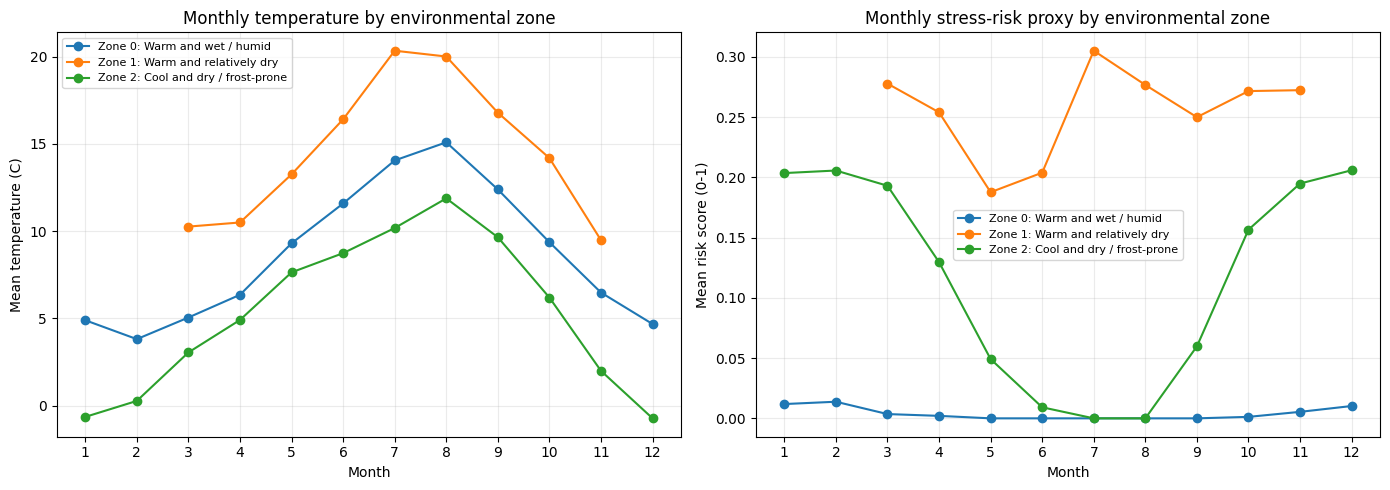

In [7]:
import matplotlib.pyplot as plt

monthly_zone = (
    model_df.assign(month_name=model_df["date"].dt.month)
    .groupby(["month_name", "environmental_zone"], as_index=False)
    .agg(mean_temperature_c=("T2M", "mean"), mean_stress_risk=("stress_risk_score", "mean"))
)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for zone, group in monthly_zone.groupby("environmental_zone"):
    label = f"Zone {zone}: {zone_labels[zone]}"
    axes[0].plot(group["month_name"], group["mean_temperature_c"], marker="o", label=label)
    axes[1].plot(group["month_name"], group["mean_stress_risk"], marker="o", label=label)
axes[0].set_title("Monthly temperature by environmental zone")
axes[0].set_ylabel("Mean temperature (C)")
axes[1].set_title("Monthly stress-risk proxy by environmental zone")
axes[1].set_ylabel("Mean risk score (0-1)")
for axis in axes:
    axis.set_xlabel("Month")
    axis.set_xticks(range(1, 13))
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8)
fig.tight_layout()
plt.show()


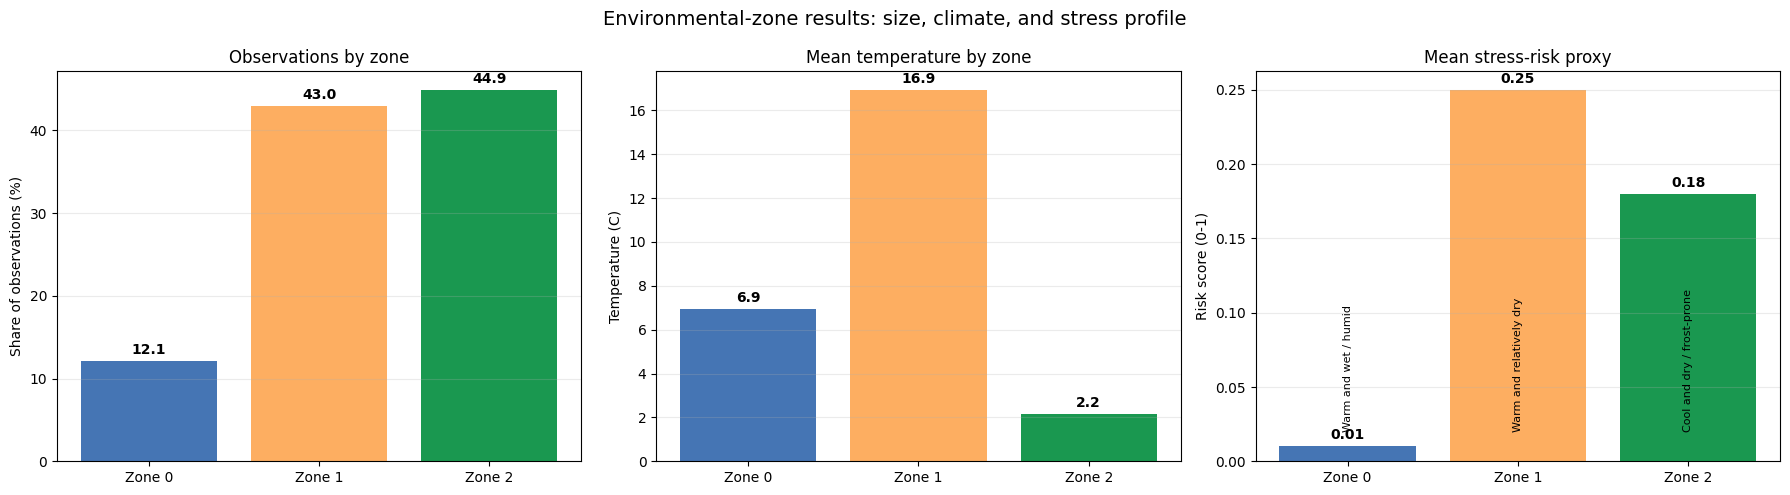

Graph labels use the detailed zone profiles calculated above:


,zone_label,observations,share_pct,T2M,PRECTOTCORR,mean_stress_risk
environmental_zone,,,,,,
0,Zone 0: Warm and wet / humid,1775,12.14,6.94,15.50,0.01
1,Zone 1: Warm and relatively dry,6281,42.97,16.93,0.55,0.25
2,Zone 2: Cool and dry / frost-prone,6560,44.88,2.17,1.98,0.18


In [8]:
zone_plot = zone_profile.copy()
zone_plot["zone_label"] = [f"Zone {zone}: {zone_labels[zone]}" for zone in zone_plot.index]
zone_plot["short_label"] = [f"Zone {zone}" for zone in zone_plot.index]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = ["#4575b4", "#fdae61", "#1a9850"]
for axis, column, title, ylabel in [
    (axes[0], "share_pct", "Observations by zone", "Share of observations (%)"),
    (axes[1], "T2M", "Mean temperature by zone", "Temperature (C)"),
    (axes[2], "mean_stress_risk", "Mean stress-risk proxy", "Risk score (0-1)"),
]:
    bars = axis.bar(zone_plot["short_label"], zone_plot[column], color=colors)
    axis.set_title(title)
    axis.set_ylabel(ylabel)
    axis.grid(axis="y", alpha=0.25)
    for bar, value, label in zip(bars, zone_plot[column], zone_plot["zone_label"]):
        axis.annotate(
            f"{value:.2f}" if column == "mean_stress_risk" else f"{value:.1f}",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 5), textcoords="offset points", ha="center", fontweight="bold",
        )
        if axis is axes[2]:
            axis.text(
                bar.get_x() + bar.get_width() / 2, 0.02, label.split(": ", 1)[1],
                ha="center", va="bottom", rotation=90, fontsize=8,
            )
fig.suptitle("Environmental-zone results: size, climate, and stress profile", fontsize=14)
fig.tight_layout()
plt.show()

print("Graph labels use the detailed zone profiles calculated above:")
display(zone_plot[["zone_label", "observations", "share_pct", "T2M", "PRECTOTCORR", "mean_stress_risk"]].round(2))


## Random Forest stress-risk baseline

Because the source has no measured crop-stress outcome, this classifier predicts a next-day environmental stress proxy. The chronological split prevents future observations from entering training. This is a pipeline smoke test, not a validated wheat model.


In [9]:
model_df["next_day_stress"] = (model_df["stress_risk_score"].shift(-1) >= 0.33).astype(int)
model_df = model_df.iloc[:-1].copy()
features = [
    "T2M", "T2M_MAX", "T2M_MIN", "RH2M", "WS2M",
    "ALLSKY_SFC_SW_DWN", "PRECTOTCORR", "month", "doy",
]
split_index = int(len(model_df) * 0.8)
X_train, X_test = model_df.loc[:split_index - 1, features], model_df.loc[split_index:, features]
y_train, y_test = model_df.loc[:split_index - 1, "next_day_stress"], model_df.loc[split_index:, "next_day_stress"]
forest = RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced")
forest.fit(X_train, y_train)
predictions = forest.predict(X_test)
print(classification_report(y_test, predictions, zero_division=0))
feature_importance = pd.Series(forest.feature_importances_, index=features).sort_values(ascending=False)
feature_importance.to_frame("importance")


              precision    recall  f1-score   support

           0       0.91      0.97      0.94      2574
           1       0.56      0.28      0.37       349

    accuracy                           0.89      2923
   macro avg       0.74      0.63      0.66      2923
weighted avg       0.87      0.89      0.87      2923



,importance
PRECTOTCORR,0.174695
T2M,0.163323
T2M_MIN,0.136584
T2M_MAX,0.125620
WS2M,0.095780
doy,0.094459
RH2M,0.092876
ALLSKY_SFC_SW_DWN,0.092220
month,0.024444


## Seasonal time-series summary and NDVI hook

Monthly summaries expose seasonal temperature, precipitation, and radiation patterns. NDVI is not present in this NASA POWER export; when a satellite-derived NDVI table is available, merge it by date and location before modeling vegetation development.


In [10]:
monthly_summary = (
    model_df.set_index("date")
    .resample("MS")
    .agg(
        mean_temperature_c=("T2M", "mean"),
        total_precipitation_mm=("PRECTOTCORR", "sum"),
        mean_solar_radiation=("ALLSKY_SFC_SW_DWN", "mean"),
        mean_stress_risk=("stress_risk_score", "mean"),
    )
    .reset_index()
)
ndvi_columns = [column for column in model_df.columns if column.upper() == "NDVI"]
if ndvi_columns:
    print(f"NDVI column available: {ndvi_columns[0]}")
else:
    print("NDVI is not in this NASA POWER export; merge a satellite NDVI dataset before NDVI analysis.")
monthly_summary.head()


NDVI is not in this NASA POWER export; merge a satellite NDVI dataset before NDVI analysis.


,date,mean_temperature_c,total_precipitation_mm,mean_solar_radiation,mean_stress_risk
0,2020-01-01,1.584476,1959.63,3.350282,0.077107
1,2020-02-01,1.279612,1006.58,7.869353,0.201713
2,2020-03-01,3.102016,650.67,12.109637,0.191286
3,2020-04-01,7.527625,346.22,17.862667,0.187746
4,2020-05-01,11.790524,981.52,19.456290,0.109912


## Model graphs

These charts summarize the exploratory climate patterns, environmental zones, stress-risk proxy, and Random Forest baseline. They are descriptive and should not be interpreted as measured wheat yield or causal effects.


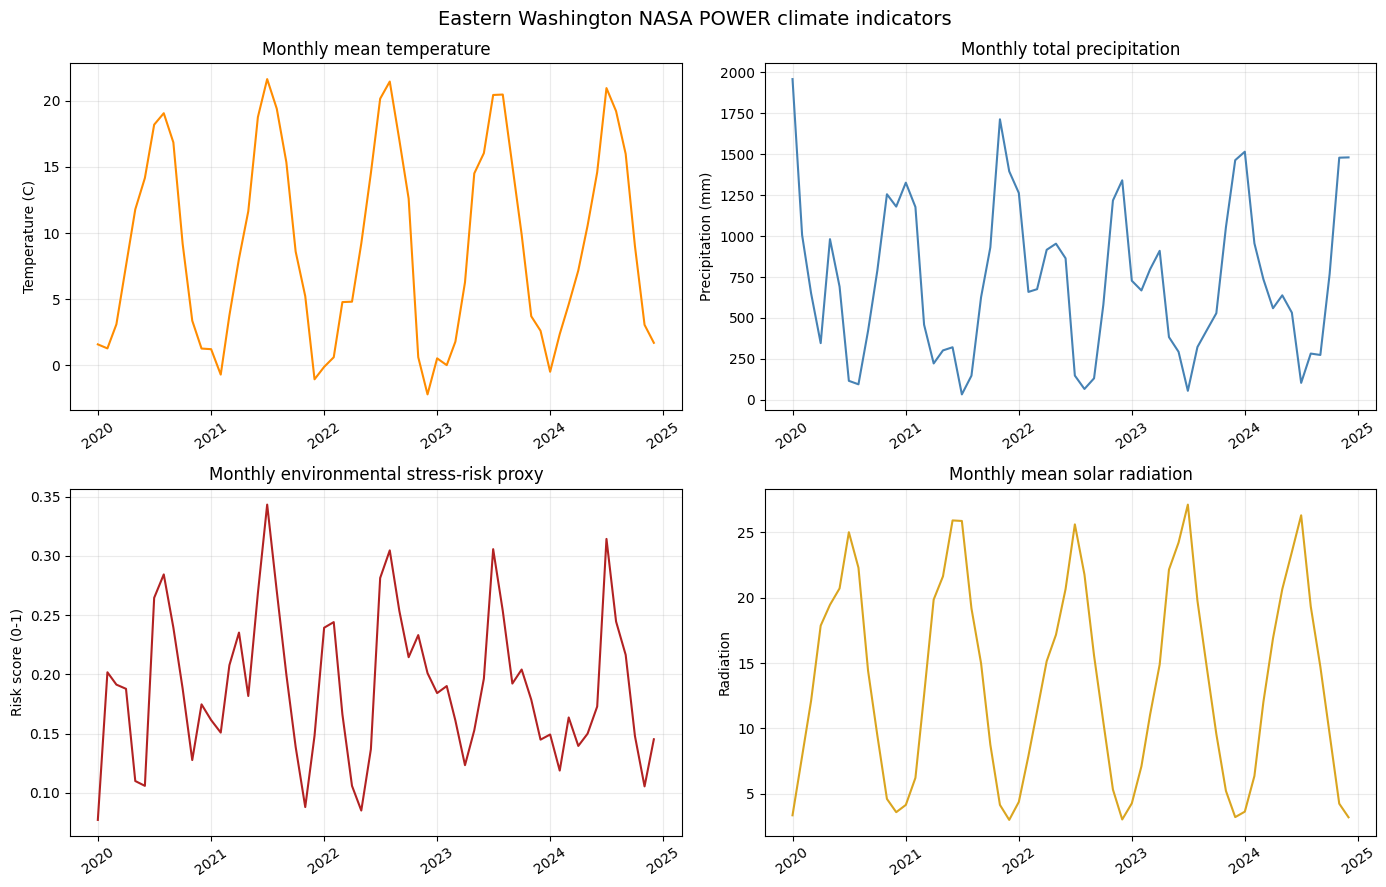

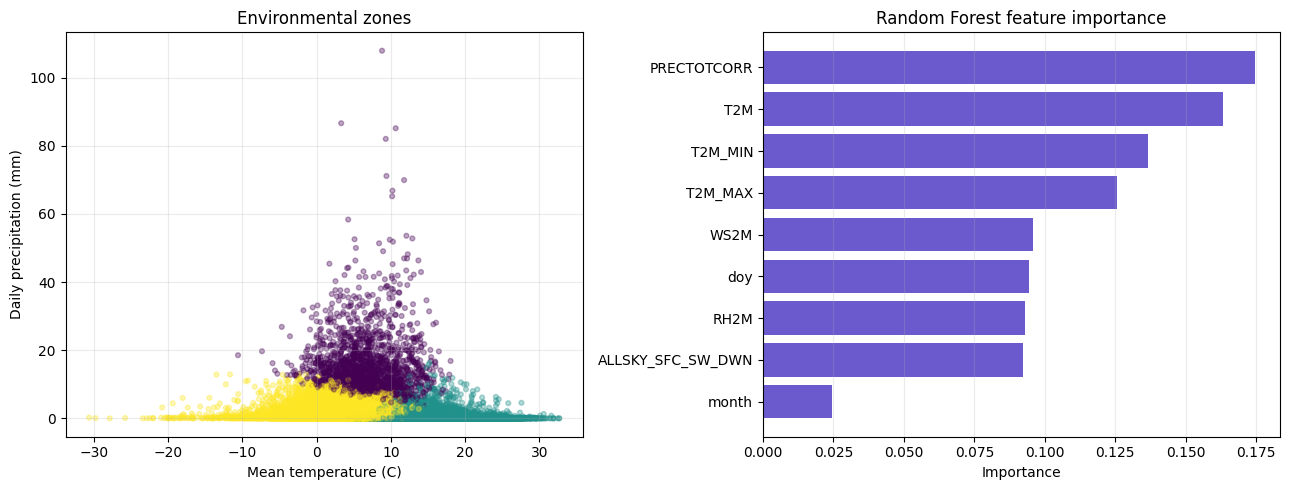

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes[0, 0].plot(monthly_summary["date"], monthly_summary["mean_temperature_c"], color="darkorange")
axes[0, 0].set_title("Monthly mean temperature")
axes[0, 0].set_ylabel("Temperature (C)")
axes[0, 1].plot(monthly_summary["date"], monthly_summary["total_precipitation_mm"], color="steelblue")
axes[0, 1].set_title("Monthly total precipitation")
axes[0, 1].set_ylabel("Precipitation (mm)")
axes[1, 0].plot(monthly_summary["date"], monthly_summary["mean_stress_risk"], color="firebrick")
axes[1, 0].set_title("Monthly environmental stress-risk proxy")
axes[1, 0].set_ylabel("Risk score (0-1)")
axes[1, 1].plot(monthly_summary["date"], monthly_summary["mean_solar_radiation"], color="goldenrod")
axes[1, 1].set_title("Monthly mean solar radiation")
axes[1, 1].set_ylabel("Radiation")
for axis in axes.flat:
    axis.tick_params(axis="x", rotation=35)
    axis.grid(alpha=0.25)
fig.suptitle("Eastern Washington NASA POWER climate indicators", fontsize=14)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(model_df["T2M"], model_df["PRECTOTCORR"], c=model_df["environmental_zone"], cmap="viridis", alpha=0.35, s=12)
axes[0].set_title("Environmental zones")
axes[0].set_xlabel("Mean temperature (C)")
axes[0].set_ylabel("Daily precipitation (mm)")
axes[0].grid(alpha=0.25)
axes[1].barh(feature_importance.index[::-1], feature_importance.values[::-1], color="slateblue")
axes[1].set_title("Random Forest feature importance")
axes[1].set_xlabel("Importance")
axes[1].grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()


## Numerical model results


In [12]:
test_metrics = pd.DataFrame({
    "accuracy": [float((predictions == y_test).mean())],
    "precision": [float(((predictions == 1) & (y_test == 1)).sum() / max((predictions == 1).sum(), 1))],
    "recall": [float(((predictions == 1) & (y_test == 1)).sum() / max((y_test == 1).sum(), 1))],
    "f1": [float(2 * ((predictions == 1) & (y_test == 1)).sum() / max((predictions == 1).sum() + (y_test == 1).sum(), 1))],
}, index=["next_day_environmental_stress_proxy"])
cluster_counts = model_df["environmental_zone"].value_counts().sort_index().rename("observations")
risk_numbers = model_df["stress_risk_score"].describe()[["mean", "50%", "max"]].rename({"50%": "median"})
print("Random Forest test metrics")
display(test_metrics.round(3))
print("Environmental-zone sizes")
display(cluster_counts.to_frame())
print("Stress-risk proxy summary")
display(risk_numbers.round(3).to_frame("value"))
print("Confusion matrix [actual rows x predicted columns]")
display(pd.DataFrame(confusion_matrix(y_test, predictions), index=["actual_low", "actual_high"], columns=["predicted_low", "predicted_high"]))


Random Forest test metrics


,accuracy,precision,recall,f1
next_day_environmental_stress_proxy,0.888,0.563,0.281,0.375


Environmental-zone sizes


,observations
environmental_zone,
0,1775
1,6281
2,6559


Stress-risk proxy summary


,value
mean,0.190
median,0.228
max,0.750


Confusion matrix [actual rows x predicted columns]


,predicted_low,predicted_high
actual_low,2498,76
actual_high,251,98


## Conclusions from this run


In [13]:
high_risk_share = float((model_df["stress_risk_score"] >= 0.66).mean())
best_feature = feature_importance.index[0]
best_zone = int(cluster_counts.idxmax())
print(f"1. The environmental stress-risk proxy averaged {model_df['stress_risk_score'].mean():.3f} and marked {high_risk_share:.1%} of observations as higher risk (score >= 0.66).")
print(f"2. The largest K-Means environmental zone was zone {best_zone}, with {int(cluster_counts.loc[best_zone])} of {len(model_df)} observations.")
print(f"3. The Random Forest baseline achieved {test_metrics.loc['next_day_environmental_stress_proxy', 'accuracy']:.1%} accuracy and {test_metrics.loc['next_day_environmental_stress_proxy', 'f1']:.3f} F1 on the chronological holdout; the strongest feature was {best_feature}.")
print("4. These metrics evaluate a next-day weather-derived proxy, not observed wheat stress, yield, or causal treatment effects.")
print("5. A credible wheat model requires labeled field outcomes, growing-stage features, NDVI or other vegetation observations, and validation across seasons and locations.")


1. The environmental stress-risk proxy averaged 0.190 and marked 0.3% of observations as higher risk (score >= 0.66).
2. The largest K-Means environmental zone was zone 2, with 6559 of 14615 observations.
3. The Random Forest baseline achieved 88.8% accuracy and 0.375 F1 on the chronological holdout; the strongest feature was PRECTOTCORR.
4. These metrics evaluate a next-day weather-derived proxy, not observed wheat stress, yield, or causal treatment effects.
5. A credible wheat model requires labeled field outcomes, growing-stage features, NDVI or other vegetation observations, and validation across seasons and locations.
